# Actividad Maxima Verosimilitud

## Alumno: Edilberto Antonio Gómez Garcia

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
faithful=sns.load_dataset("geyser")
x=faithful["waiting"].dropna().to_numpy()
x

array([79, 54, 74, 62, 85, 55, 88, 85, 51, 85, 54, 84, 78, 47, 83, 52, 62,
       84, 52, 79, 51, 47, 78, 69, 74, 83, 55, 76, 78, 79, 73, 77, 66, 80,
       74, 52, 48, 80, 59, 90, 80, 58, 84, 58, 73, 83, 64, 53, 82, 59, 75,
       90, 54, 80, 54, 83, 71, 64, 77, 81, 59, 84, 48, 82, 60, 92, 78, 78,
       65, 73, 82, 56, 79, 71, 62, 76, 60, 78, 76, 83, 75, 82, 70, 65, 73,
       88, 76, 80, 48, 86, 60, 90, 50, 78, 63, 72, 84, 75, 51, 82, 62, 88,
       49, 83, 81, 47, 84, 52, 86, 81, 75, 59, 89, 79, 59, 81, 50, 85, 59,
       87, 53, 69, 77, 56, 88, 81, 45, 82, 55, 90, 45, 83, 56, 89, 46, 82,
       51, 86, 53, 79, 81, 60, 82, 77, 76, 59, 80, 49, 96, 53, 77, 77, 65,
       81, 71, 70, 81, 93, 53, 89, 45, 86, 58, 78, 66, 76, 63, 88, 52, 93,
       49, 57, 77, 68, 81, 81, 73, 50, 85, 74, 55, 77, 83, 83, 51, 78, 84,
       46, 83, 55, 81, 57, 76, 84, 77, 81, 87, 77, 51, 78, 60, 82, 91, 53,
       78, 46, 77, 84, 49, 83, 71, 80, 49, 75, 64, 76, 53, 94, 55, 76, 50,
       82, 54, 75, 78, 79

### 1. Antes de estimar un modelo, examine la forma de la distribución.

a) Obtenga el número de observaciones, la media, la desviación estándar, la mediana y
los cuartiles de waiting.

b) Construya un histograma y agregue una curva de densidad. ¿La forma observada
parece compatible con una sola distribución normal?

c) A partir de la gráfica, identifique si existe evidencia visual de más de un grupo o
régimen de tiempos de espera.

In [67]:
# a)
num_obs = len(x)
media_obs = x.mean()
des_est = x.std()
mediana_obs = np.median(x)
q1_obs = np.quantile(x, 0.25)
q3_obs = np.quantile(x, 0.75)

print(f'Numero de observaciones: {num_obs}')
print(f'La media de las observaciones: {media_obs}')
print(f'La desviación estándar de las obervaciones: {des_est}')
print(f'La mediana de las observaciones: {mediana_obs}')
print(f'El primer cuartil de las observaciones: {q1_obs}')
print(f'El tercer cuartil de las observaciones: {q3_obs}')

Numero de observaciones: 272
La media de las observaciones: 70.8970588235294
La desviación estándar de las obervaciones: 13.569960017586371
La mediana de las observaciones: 76.0
El primer cuartil de las observaciones: 58.0
El tercer cuartil de las observaciones: 82.0


Text(0, 0.5, 'Frecuencia')

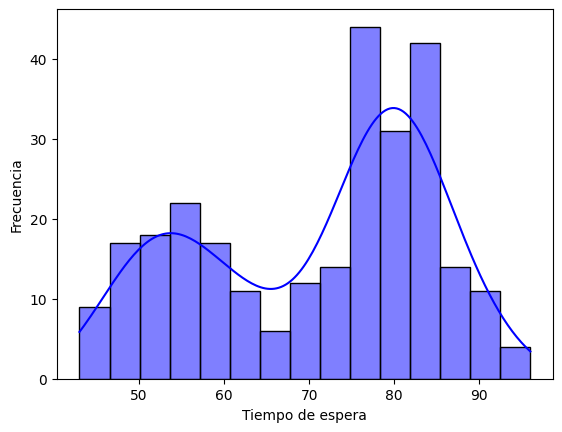

In [12]:
# b)
sns.histplot(x, kde=True, color='blue', bins=15)
plt.xlabel('Tiempo de espera')
plt.ylabel('Frecuencia')

### c)
La gráfica si parece tener una distribución normal, pero no solamente una gráfica normal, si no 2 grupos, uno para tiempo de espera corto, y otro para tiempo de espera más largos.

### 2

In [17]:
# a)
estimador_media = sum(x)/len(x)
estimador_varianza = np.var(x)

In [ ]:
from scipy.stats import norm
# b)
log_verosimilitud = np.sum(norm.logpdf(x, loc=estimador_media, scale=np.sqrt(estimador_varianza)))
print(f"Log-verosimilitud: {log_verosimilitud}")

Log-verosimilitud: -1095.2888005007117


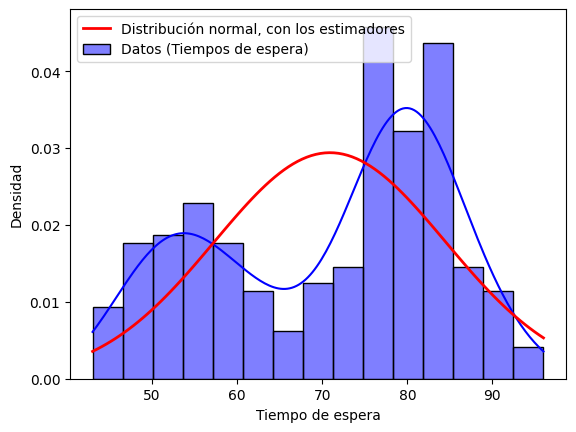

In [ ]:
# c)

sns.histplot(x, stat='density', kde=True, color='blue', bins=15, alpha=0.5, label='Datos (Tiempos de espera)')

x_min, x_max = np.min(x), np.max(x)
x_grid = np.linspace(x_min, x_max, 100)
densidad_normal = norm.pdf(x_grid, loc=estimador_media, scale=np.sqrt(estimador_varianza))
plt.plot(x_grid, densidad_normal, color='red', linewidth=2, label='Distribución normal, con los estimadores')

plt.xlabel('Tiempo de espera')
plt.ylabel('Densidad')
plt.legend()

No logra representar adecuadamente los dos picos de mayor frecuencia, es decir, como una bimodalidad, ya que la normal sólo tiene un punto alto, cuando los datos nos indican que tiene al menos 2.

### 3.-

#### a)
$\pi$ representa la proporción de los datos observados a uno grupo o al otro, lo podemos ver cuando una distribución se multiplica por $\pi$ y la otra distribución se multiplica por $(1-\pi)$ y es por eso de $\pi$ va de 0 a 1.

y tanto $\mu_1$ como $\mu_2$ representan los tiempos promedios de espera de cada grupo.

#### b)

$$L = \sum^n_{i=1} In[\pi (\frac{1}{\sqrt{2\pi \sigma^2_1}}exp(-\frac{(x_i-\mu_1)^2}{2\sigma_1^2})) + (1-\pi) (\frac{1}{\sqrt{2\pi \sigma^2_2}}exp(-\frac{(x_i-\mu_2)^2}{2\sigma_2^2}))]$$

In [32]:
def mezcla_norm(x, pi, mu1, mu2, s1, s2):
    return np.sum(np.log(pi * stats.norm.pdf(x, mu1, s1) + (1 - pi) * stats.norm.pdf(x, mu2, s2)))

### 4

In [43]:
n = len(x)

pi = 0.50
mu1 = 55.0
mu2 = 80.0

sigma1 = 10.0 
sigma2 = 10.0 

max_iter = 1000
tol = 1e-4
log_prev = -np.inf
log_list = []

for i in range(max_iter):

    densidad_1 = norm.pdf(x, loc=mu1, scale=sigma1)
    densidad_2 = norm.pdf(x, loc=mu2, scale=sigma2)
    
    num = pi * densidad_1
    den = num + (1 - pi) * densidad_2
    
    tau = num / den
    
    log = np.sum(np.log(den))
    
    if np.abs(log - log_prev) < tol:
        break
        
    log_prev = log
    log_list.append(log)
    
    sum_tau = np.sum(tau)
    pi = sum_tau / n

    sum_1_menos_tau = np.sum(1 - tau)
    
    mu1 = np.sum(tau * x) / sum_tau
    mu2 = np.sum((1 - tau) * x) / sum_1_menos_tau
    
    var1 = np.sum(tau * (x - mu1)**2) / sum_tau
    var2 = np.sum((1 - tau) * (x - mu2)**2) / sum_1_menos_tau
    
    sigma1 = np.sqrt(var1)
    sigma2 = np.sqrt(var2)


### 5

In [ ]:
print(f"Número de iteraciones : {i}\n")
print(f"(pi) : {pi:.4f}\n")
print(f"Media 1 (mu1)    : {mu1:.4f}")
print(f"Varianza 1       : {var1:.4f} (Sigma1: {sigma1:.4f})\n")
print(f"Media 2 (mu2)    : {mu2:.4f}")
print(f"Varianza 2       : {var2:.4f} (Sigma2: {sigma2:.4f})\n")
print(f"Log-verosimilitud final: {log:.4f}")

Número de iteraciones : 15

(pi) : 0.3610
(1-pi): 0.6390

Media 1 (mu1)    : 54.6187
Varianza 1       : 34.5100 (Sigma1: 5.8745)

Media 2 (mu2)    : 80.0935
Varianza 2       : 34.4018 (Sigma2: 5.8653)

Log-verosimilitud final: -1034.0018


### 6

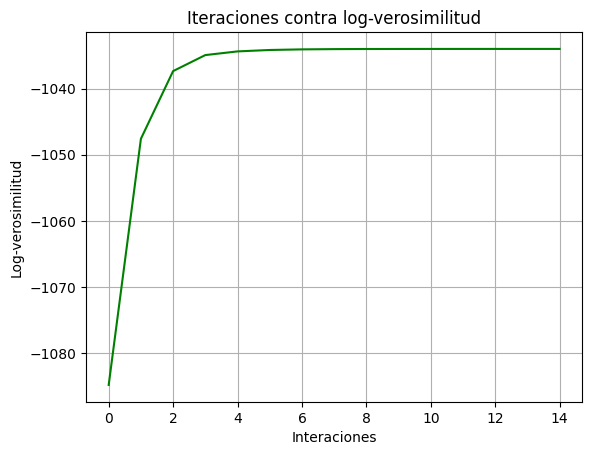

In [47]:
plt.plot(log_list, color='green')
plt.xlabel('Interaciones')
plt.ylabel('Log-verosimilitud')
plt.title('Iteraciones contra log-verosimilitud')
plt.grid()

### 7

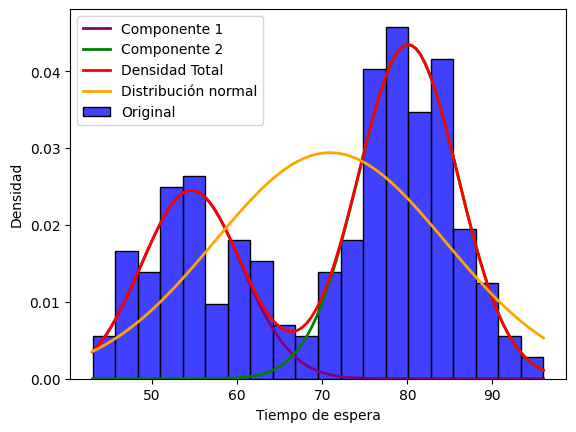

In [53]:
sns.histplot(x, stat='density', color='blue', bins=20, label='Original')

componente_1 = pi * norm.pdf(x_grid, loc=mu1, scale=sigma1)
componente_2 = (1 - pi) * norm.pdf(x_grid, loc=mu2, scale=sigma2)

densidad_total = componente_1 + componente_2

plt.plot(x_grid, componente_1, color='purple', lw=2, label='Componente 1')
plt.plot(x_grid, componente_2, color='green', lw=2, label='Componente 2')
plt.plot(x_grid, densidad_total, color='red', lw=2, label='Densidad Total')
plt.plot(x_grid, densidad_normal, color='orange', linewidth=2, label='Distribución normal')

plt.xlabel('Tiempo de espera')
plt.ylabel('Densidad')
plt.legend()

Aporta la mejora de que ahora si podemos observar los dos picos de frecuencia que se tienen el histograma

In [54]:
clasificacion_grupo1 = tau > 0.5

n_grupo1 = np.sum(clasificacion_grupo1)
n_grupo2 = len(x) - n_grupo1  

print(f"Observaciones clasificadas al Componente 1: {n_grupo1}")
print(f"Observaciones clasificadas al Componente 2: {n_grupo2}")

Observaciones clasificadas al Componente 1: 99
Observaciones clasificadas al Componente 2: 173


### 8

In [58]:
def calcular_bic_aic(log_verosimilitud, n, k):

    aic=-2 * log_verosimilitud + 2 * k
    bic=-2 * log_verosimilitud + k * np.log(n)

    return bic, aic

In [ ]:
k_normal = 2 #mu y sigma
bic_normal, aic_normal = calcular_bic_aic(log_verosimilitud, n, k_normal)

k_mezcla = 5 #mu_1, sigm_1, mu_2, sigma_2 y pi
bic_mezcla, aic_mezcla = calcular_bic_aic(log, n, k_mezcla)

print(f"Normal, AIC: {aic_normal:.2f} y BIC: {bic_normal:.2f}")
print(f"Mezcla, AIC: {aic_mezcla:.2f} y BIC: {bic_mezcla:.2f}")

Normal, AIC: 2194.58 y BIC: 2201.79
Mezcla, AIC: 2078.00 y BIC: 2096.03


### 9

In [60]:
from sklearn.mixture import GaussianMixture

gmm=GaussianMixture(n_components=2, random_state=2026)
gmm.fit(x.reshape(-1, 1))

print("Pesos:", gmm.weights_)
print("Medias:", gmm.means_.ravel())
print("Desviaciones:", np.sqrt(gmm.covariances_.ravel()))

Pesos: [0.63654233 0.36345767]
Medias: [80.14546556 54.69984271]
Desviaciones: [5.81293521 5.94286542]


In [ ]:
resultados = {'Algoritmo EM': [pi, mu1, sigma1, mu2, sigma2],
                'GaussianMixture':[gmm.weights_[1], gmm.means_.ravel()[1], np.sqrt(gmm.covariances_.ravel())[1], gmm.means_.ravel()[0], np.sqrt(gmm.covariances_.ravel())[0]]}

resultados = pd.DataFrame(resultados, index=['pi', 'mu_1', 'sigma_1', 'mu_2', 'sigma_2'])
resultados

,Algoritmo EM,GaussianMixture
pi,0.361002,0.363458
mu_1,54.618711,54.699843
sigma_1,5.874519,5.942865
mu_2,80.093508,80.145466
sigma_2,5.865301,5.812935
